# Student dropout & academic success – full pipeline on Google Colab

Cost-sensitive soft-voting ensemble (LightGBM, CatBoost, XGBoost, ExtraTrees) on UCI dataset 697, compared with Islam et al. (2025) under three evaluation protocols.

## 1. Get the code and install packages

In [ ]:
REPO_URL = "https://github.com/ntvy243/dropout-prediction"
import os
if not os.path.exists('/content/dropout-prediction'):
    !git clone $REPO_URL /content/dropout-prediction
%cd /content/dropout-prediction
!pip install -q -r requirements.txt
!python src/download_data.py   # only downloads if data/data.csv is missing

Cloning into '/content/dropout-prediction'...
remote: Enumerating objects: 160, done.
remote: Counting objects: 100% (160/160), done.
remote: Compressing objects: 100% (158/158), done.
remote: Total 160 (delta 21), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (160/160), 6.78 MiB | 14.81 MiB/s, done.
Resolving deltas: 100% (21/21), done.
/content/dropout-prediction
data/data.csv already present


## 2. (Optional) save results to Google Drive so they survive a session reset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs('/content/drive/MyDrive/AI_Class/dropout_results', exist_ok=True)
os.environ['RESULTS_DIR'] = '/content/drive/MyDrive/AI_Class/dropout_results/results'   # figures go to the parent folder
os.environ['N_JOBS'] = str(os.cpu_count())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Quick smoke test (reduced settings, a few minutes)

In [ ]:
!python src/run_all.py --fast


==================== [1/11] run_protocol_a.py  (0.0 min elapsed)
ExtraTrees (sqrt)        CV acc 0.8325
LightGBM (63 leaves)     CV acc 0.8432
XGBoost (depth 8)        CV acc 0.8402
XGBoost paper default    CV acc 0.8315
ensemble members: ['LightGBM (63 leaves)', 'XGBoost (depth 8)', 'ExtraTrees (sqrt)']
0 {'XGBoost paper default': 0.8446, 'LightGBM (63 leaves)': 0.8597, 'XGBoost (depth 8)': 0.8499, 'ExtraTrees (sqrt)': 0.8454, 'ENSEMBLE top-3 (ours)': 0.8575}
1 {'XGBoost paper default': 0.8198, 'LightGBM (63 leaves)': 0.8439, 'XGBoost (depth 8)': 0.8348, 'ExtraTrees (sqrt)': 0.8454, 'ENSEMBLE top-3 (ours)': 0.8446}
                   model  mean_accuracy  std_accuracy  mean_macro_f1  mean_f1_Enrolled  diff_vs_0_83  p_vs_0_83  diff_vs_paper_model  paired_p  wins  seeds
0  XGBoost paper default         0.8322        0.0176         0.8321            0.8132        0.0022     0.8885                  NaN       NaN   NaN    NaN
1   LightGBM (63 leaves)         0.8518        0.0112         0

## 4. Full run (long). Run stages one at a time if the session may time out

In [ ]:
# !python src/run_all.py                    # everything
# or stage by stage:
# !python src/run_protocol_a.py              # 1 Islam et al. protocol (leaky), 10 seeds
# !python src/run_protocol_b.py              # 2
# !python src/run_protocol_c.py              # 3 leakage-free, Optuna, SHAP, fairness
# !python src/run_paper3_compare.py          # 4 proposed model v1/v2
# !python src/run_islam_fair.py              # 5 Islam pipeline without leakage
# !python src/run_ablation.py                # 6
# !python src/run_protocol_a_v2.py           # 7
# !python src/stats_islam.py                 # 8
# !python src/holdout_artifacts.py           # 9
# !python src/make_figures.py                # 10
# !python src/make_paper_figures.py          # 11

## 5. Look at the results

In [ ]:
import pandas as pd, os
R = os.environ.get('RESULTS_DIR', 'results')
print('Leakage-free tests vs Islam et al. (proposed model minus baseline):')
display(pd.read_csv(f'{R}/islam_fair_tests.csv').round(4))

Leakage-free tests vs Islam et al. (proposed model minus baseline):


,kind,ours,baseline,metric,diff,p,wins,n
0,cv,OURS v1 (balanced weights),Islam XGB (fair),accuracy,0.0115,NaN,4,15
1,cv,OURS v1 (balanced weights),Islam XGB (fair),macro_f1,0.0313,NaN,5,15
2,cv,OURS v1 (balanced weights),Islam XGB (fair),f1_Enrolled,0.0692,NaN,5,15
3,cv,OURS v1 (balanced weights),Islam XGB (fair),recall_Enrolled,0.1423,NaN,5,15
4,cv,OURS v1 (balanced weights),Islam RF (fair),accuracy,0.0165,NaN,5,15
...,...,...,...,...,...,...,...,...
59,holdout,OURS v2 (sqrt weights),Islam GB (fair),recall_Enrolled,0.0189,NaN,1,11
60,holdout,OURS v2 (sqrt weights),Islam DT (fair),accuracy,0.1096,NaN,1,11
61,holdout,OURS v2 (sqrt weights),Islam DT (fair),macro_f1,0.1053,NaN,1,11
62,holdout,OURS v2 (sqrt weights),Islam DT (fair),f1_Enrolled,0.1292,NaN,1,11


paper_figures/fig10_shap.png


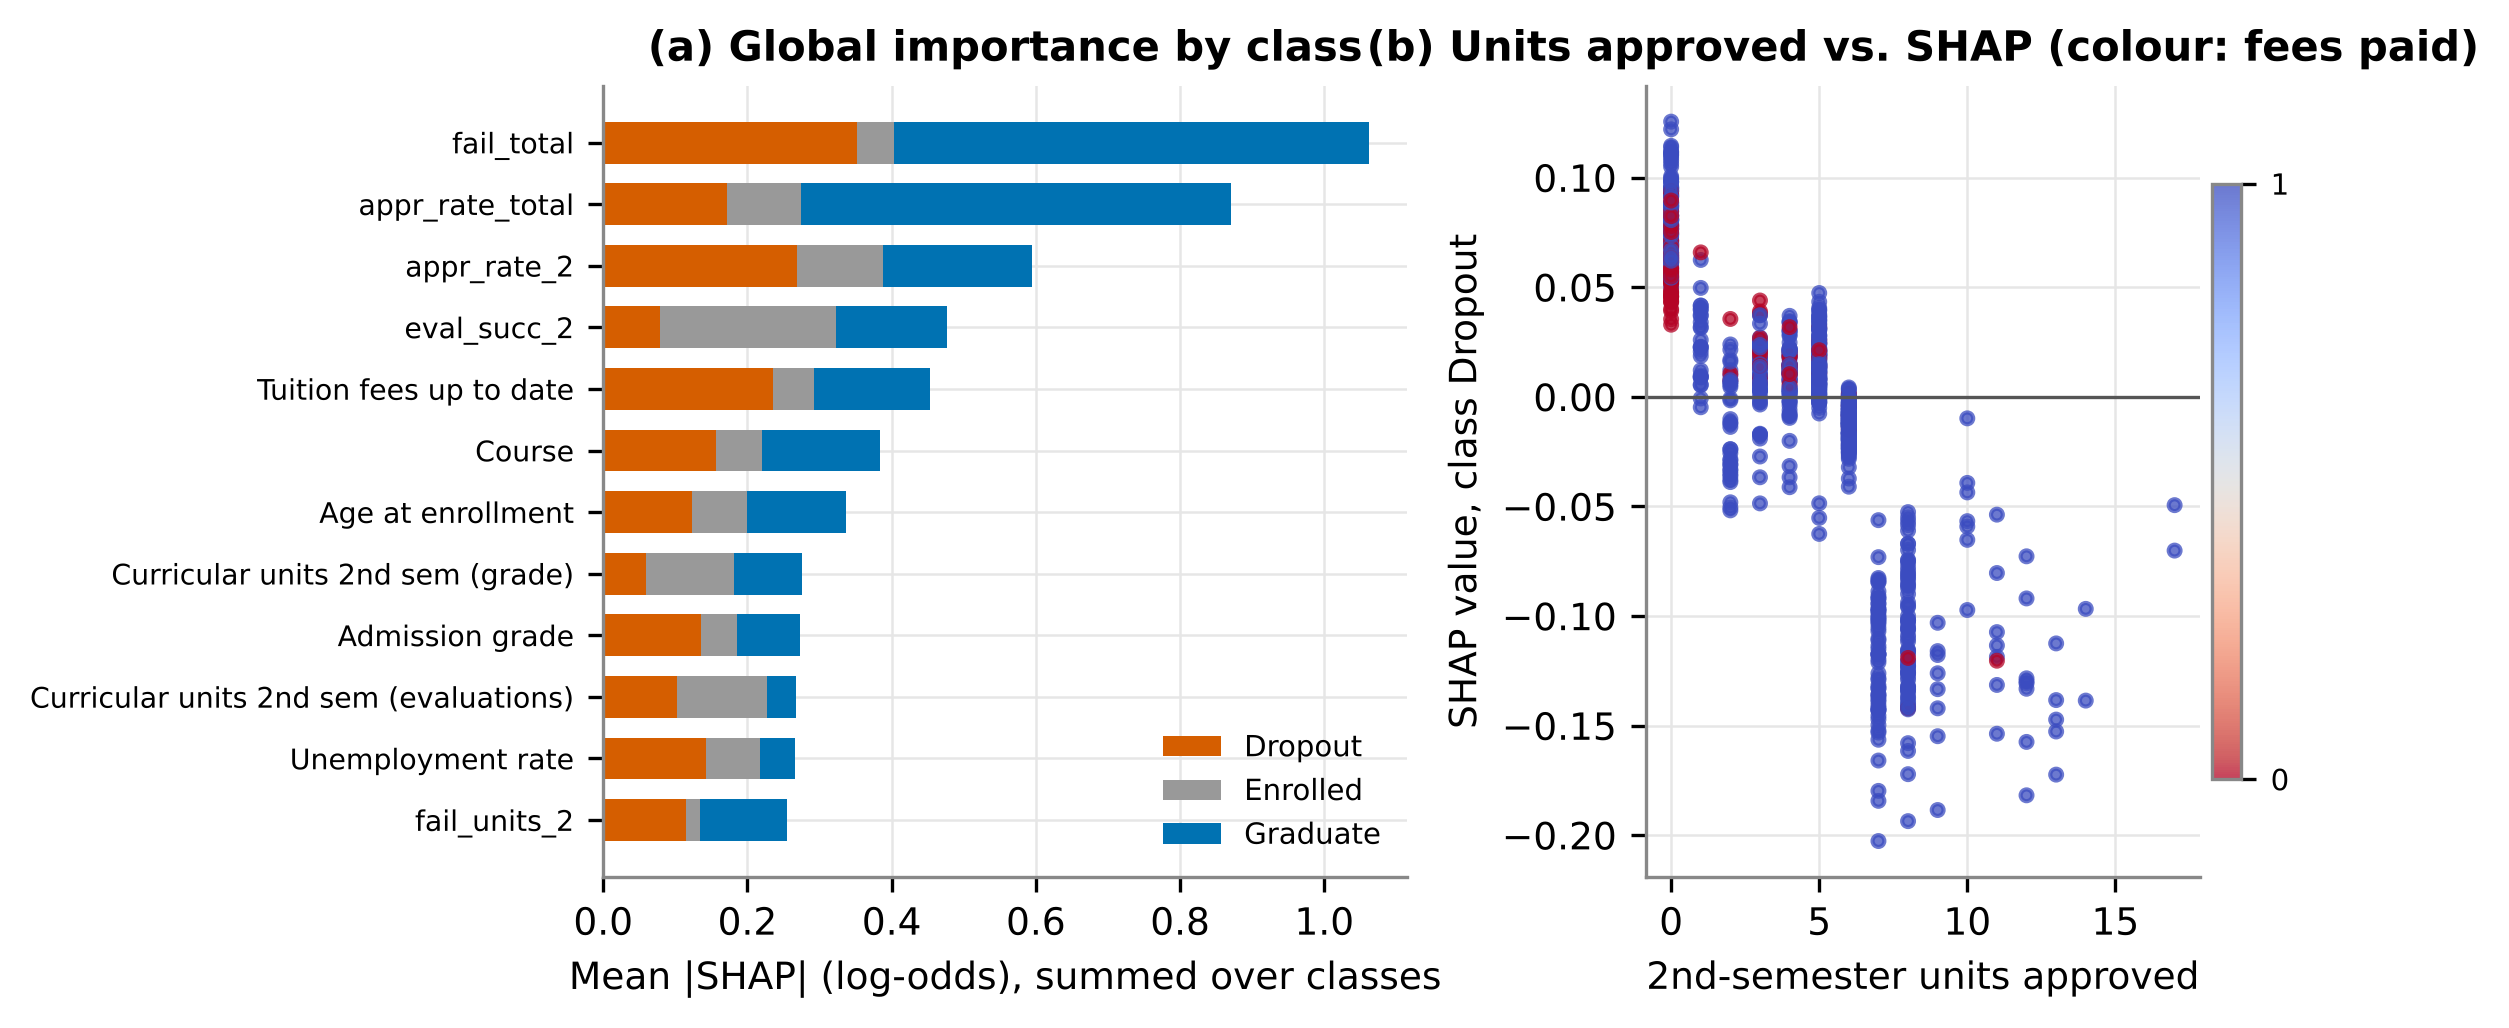

paper_figures/fig11_subgroups.png


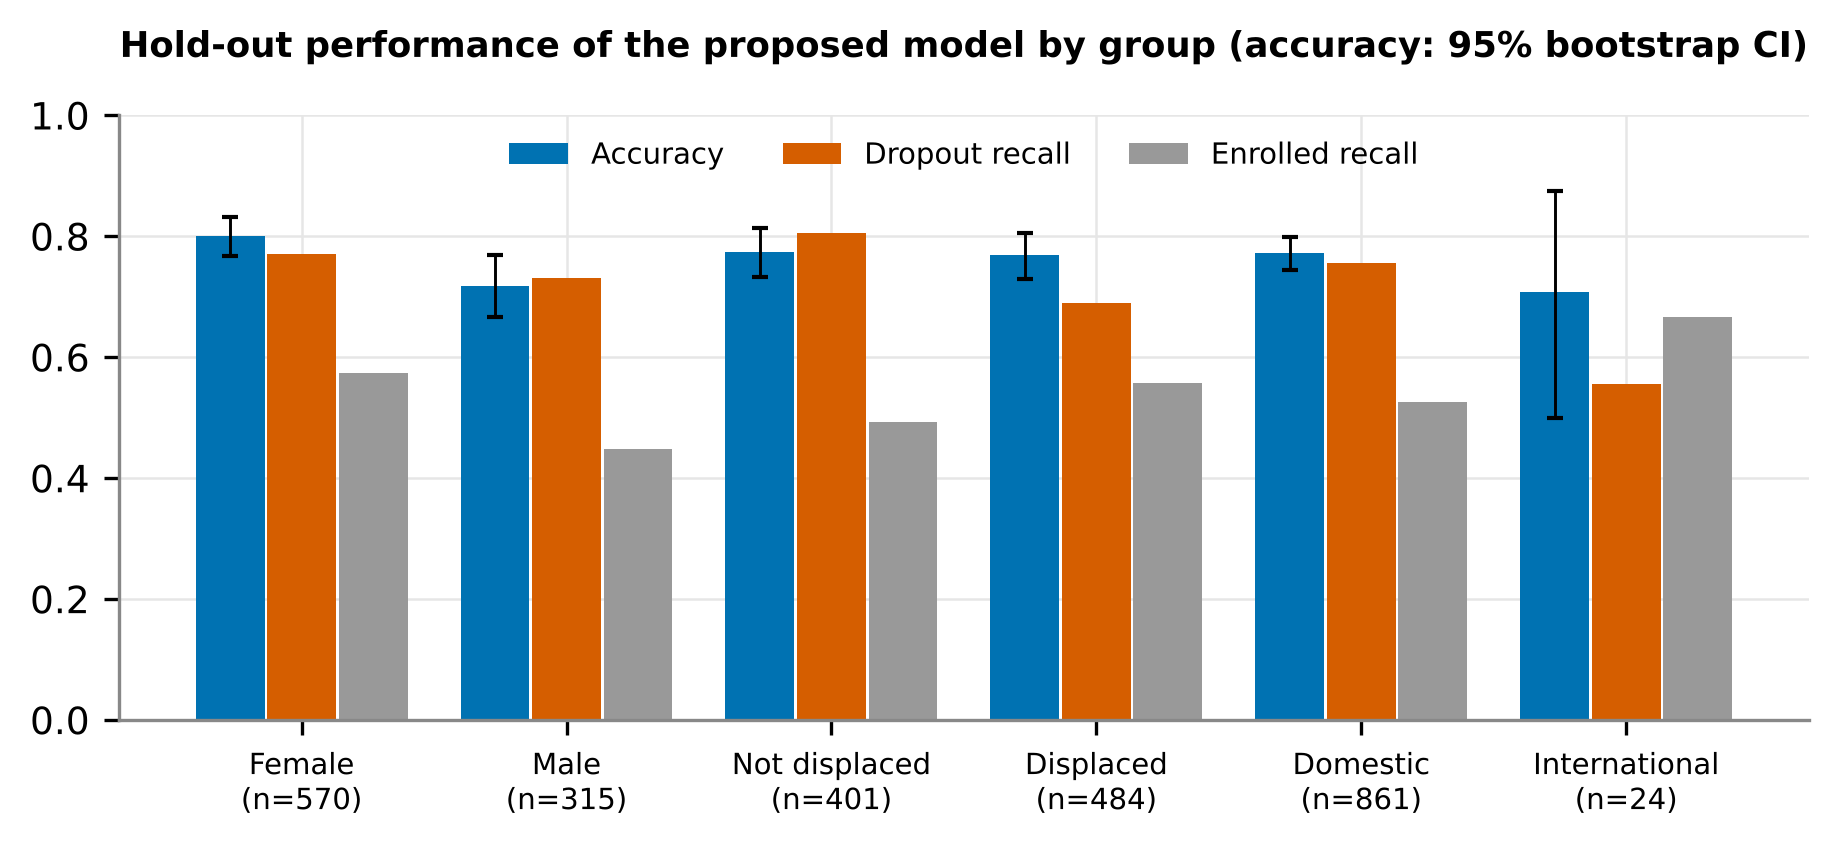

paper_figures/fig1_workflow.png


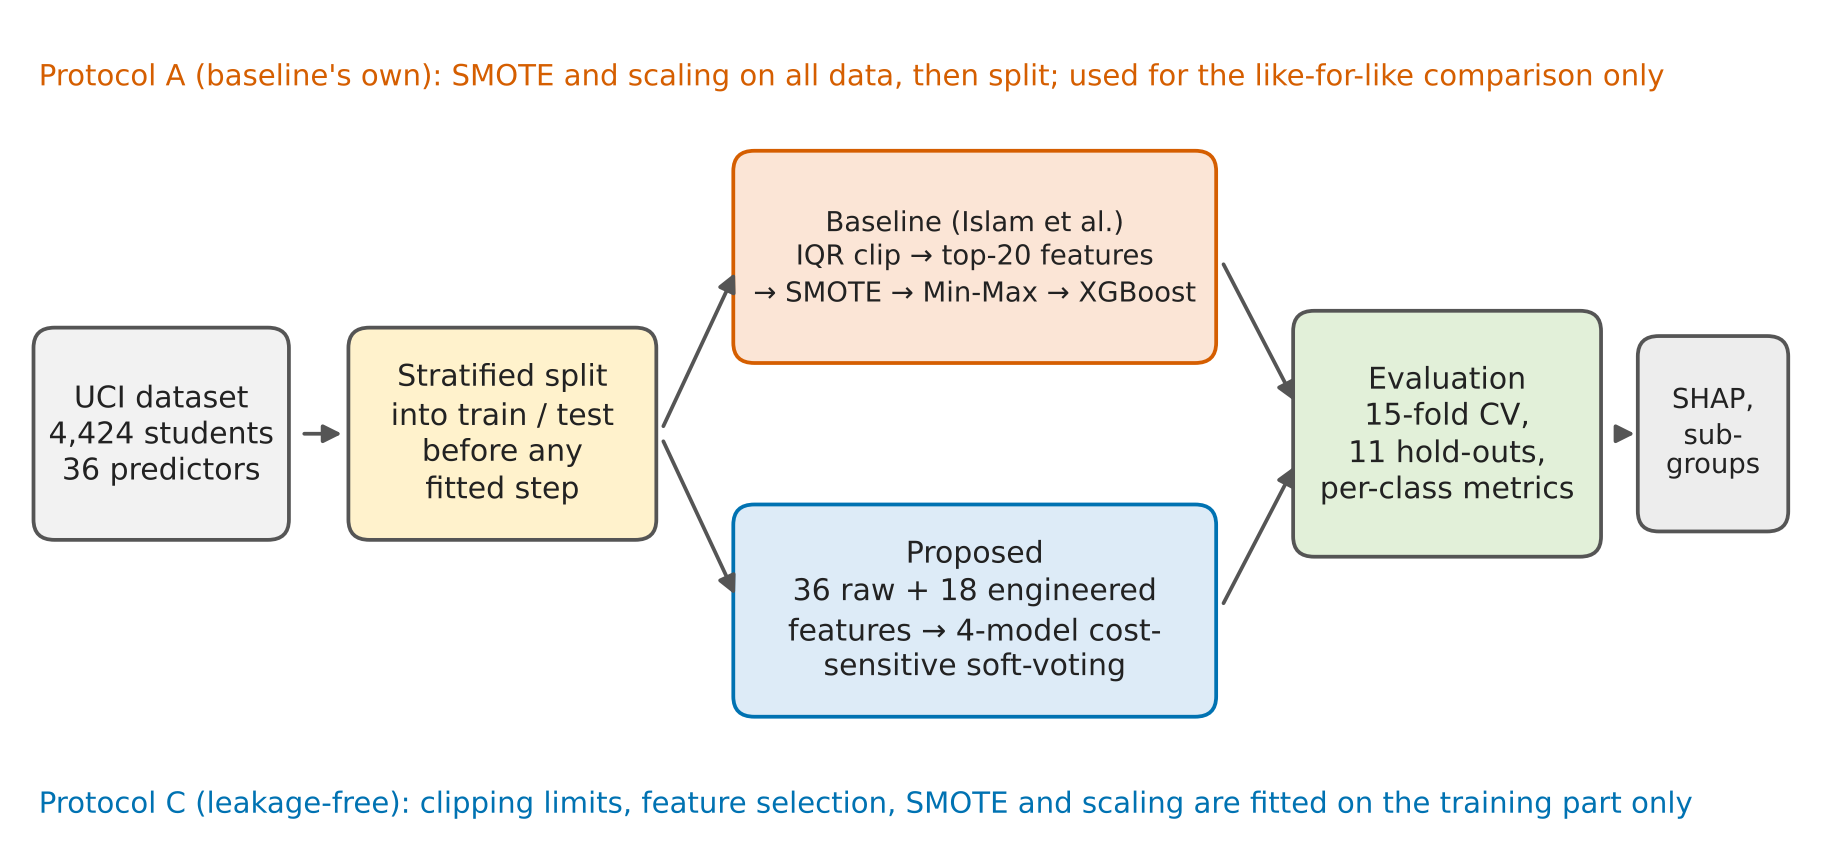

paper_figures/fig2_eda.png


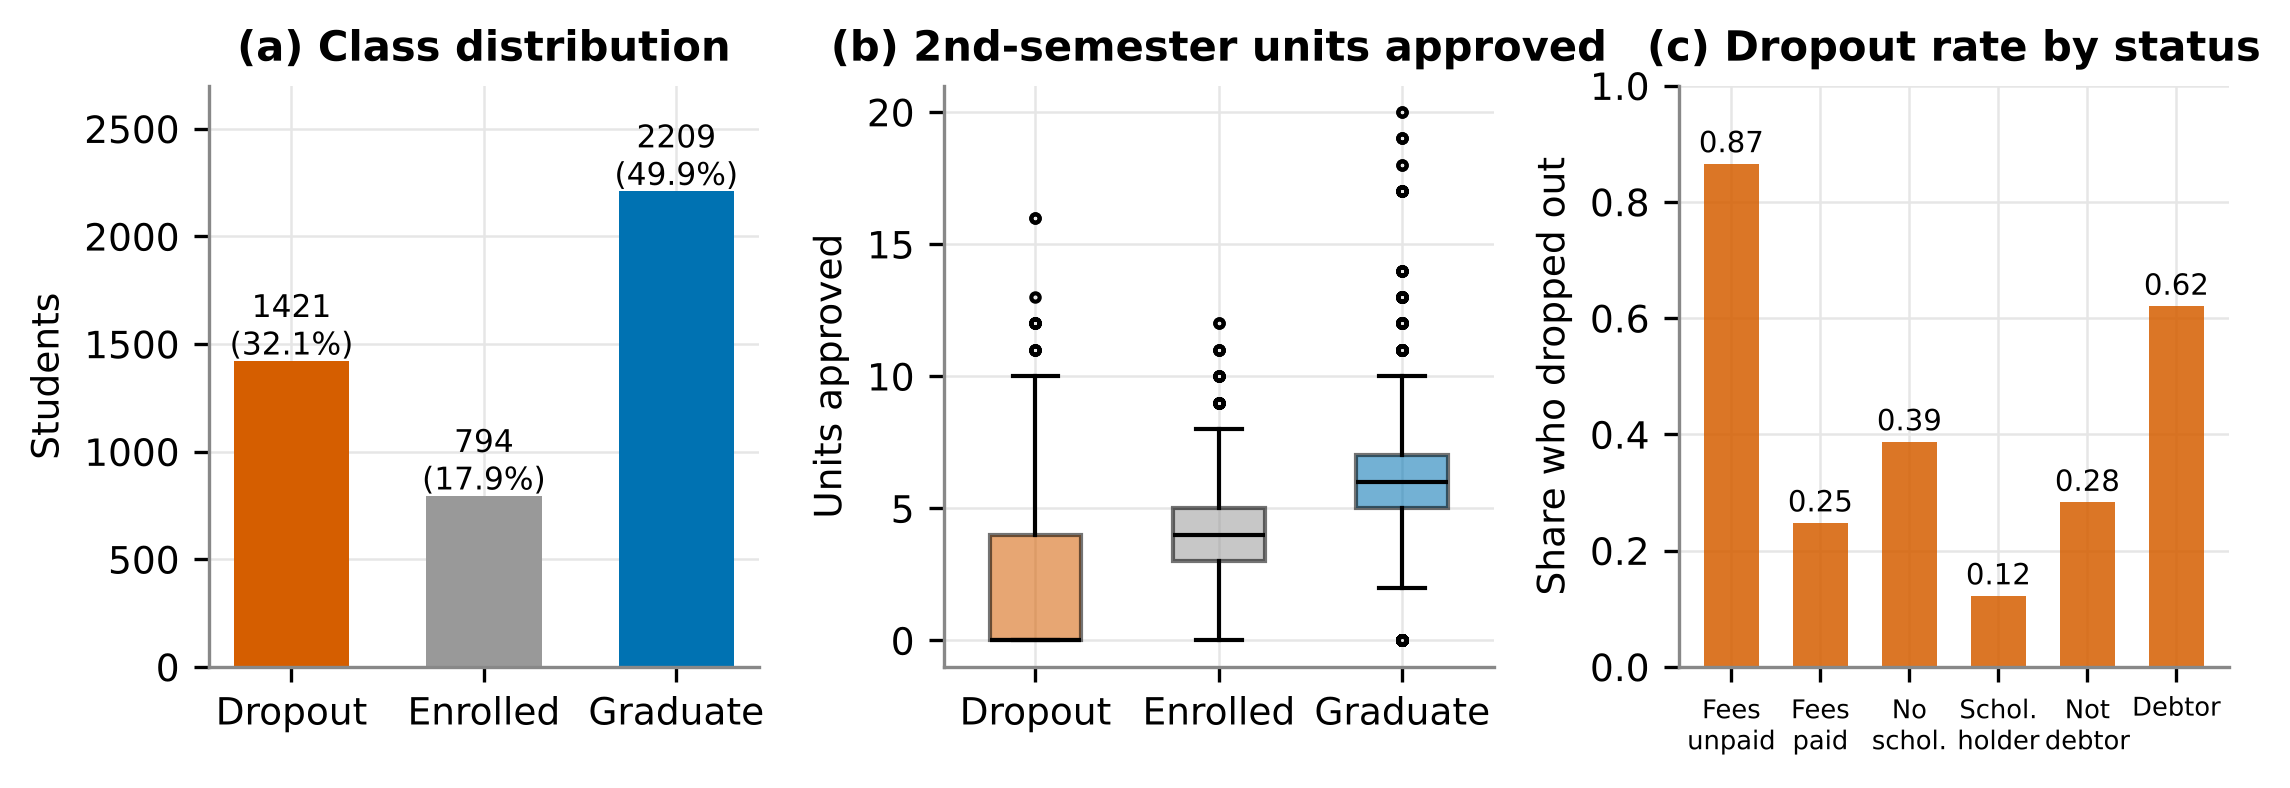

paper_figures/fig3_headline.png


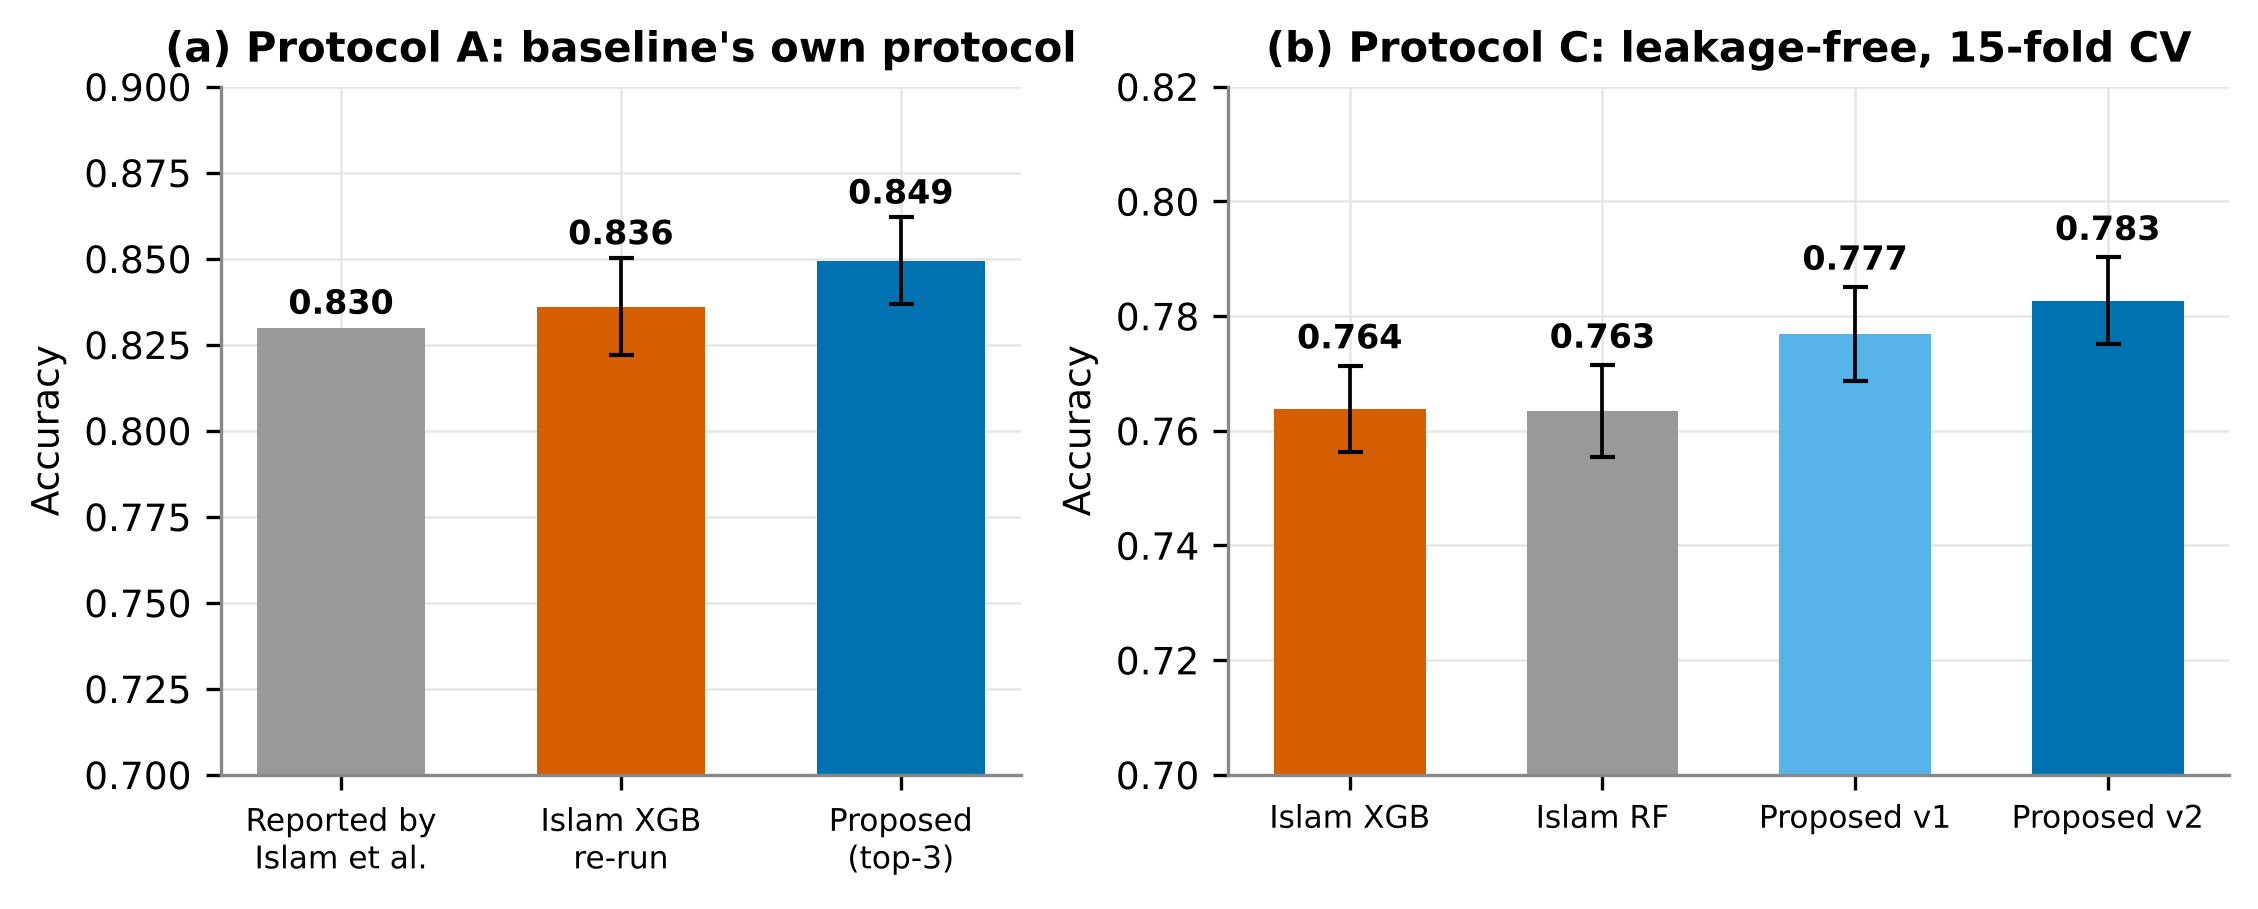

paper_figures/fig4_protocolA_seeds.png


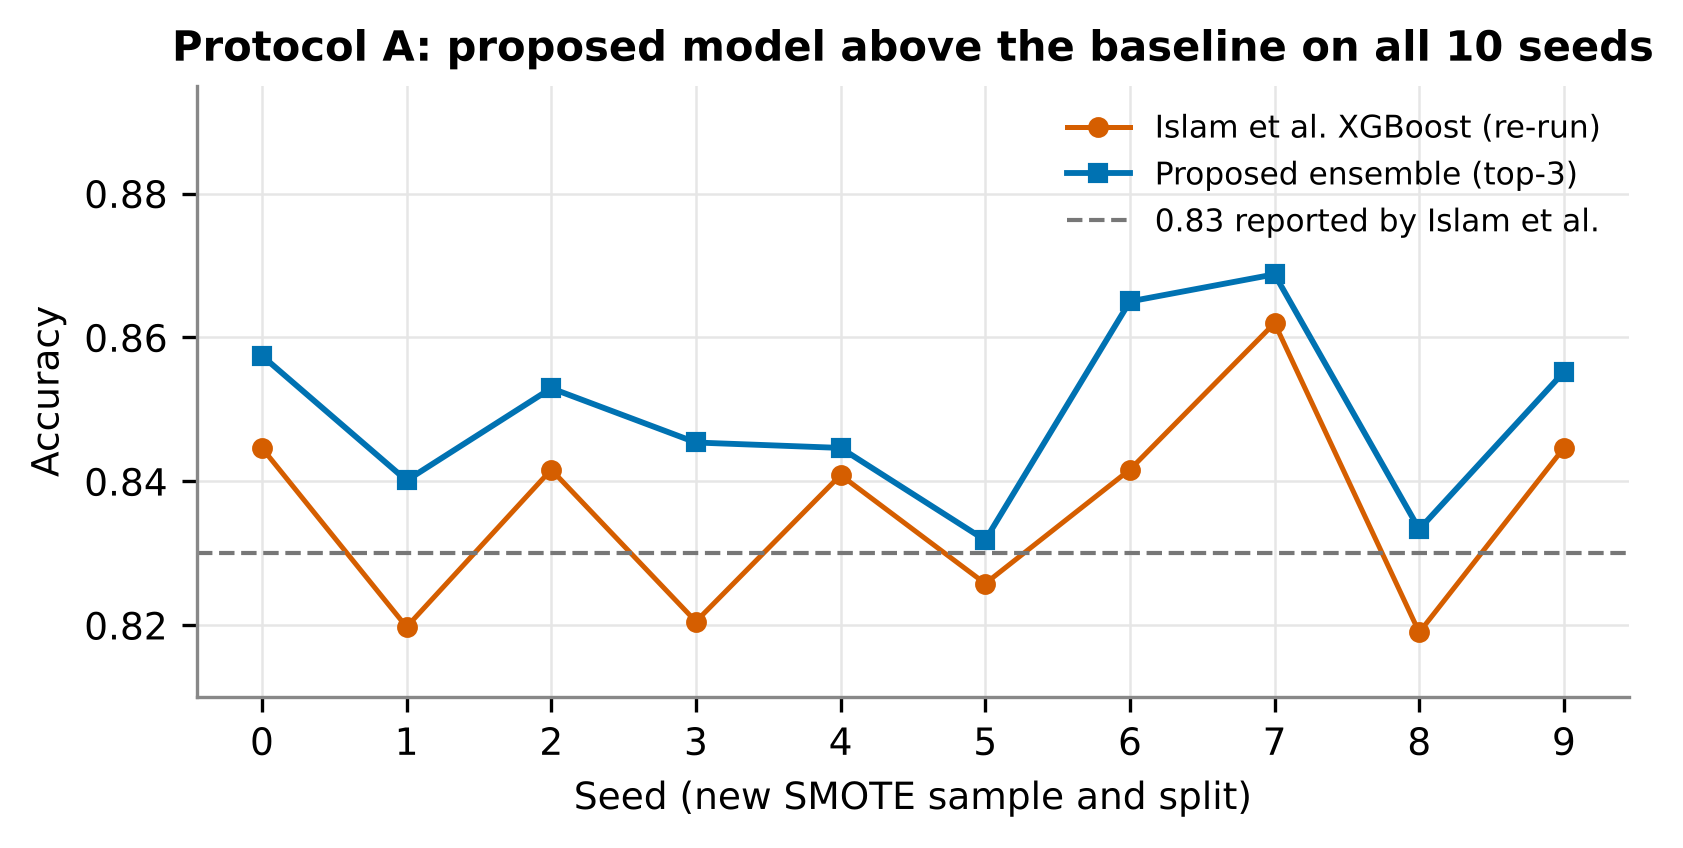

paper_figures/fig5_leakage.png


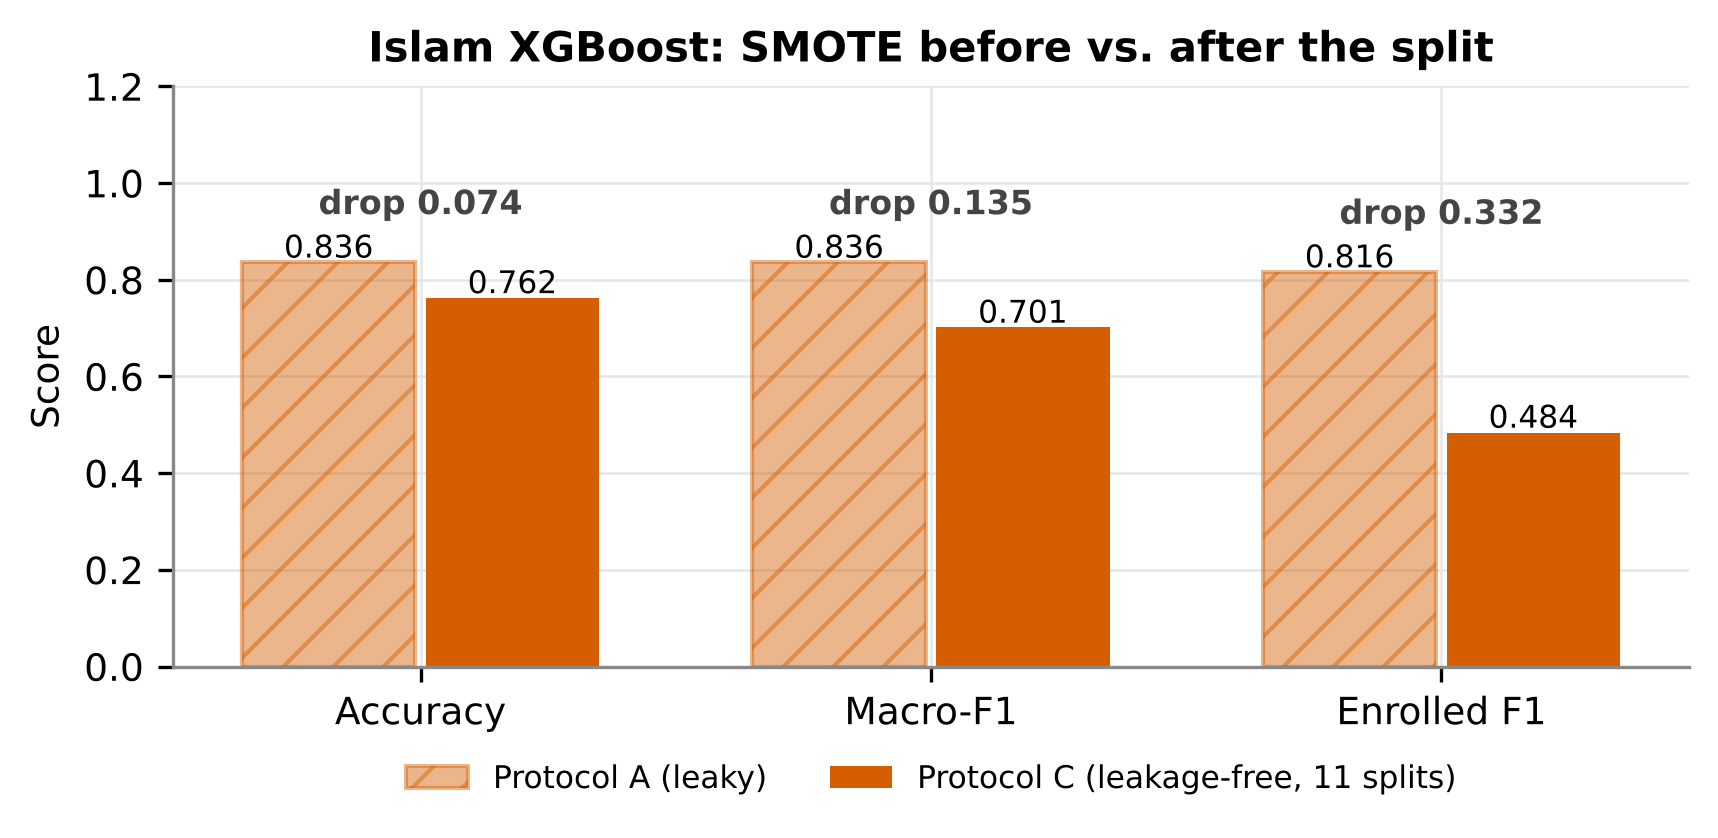

paper_figures/fig6_fair_metrics.png


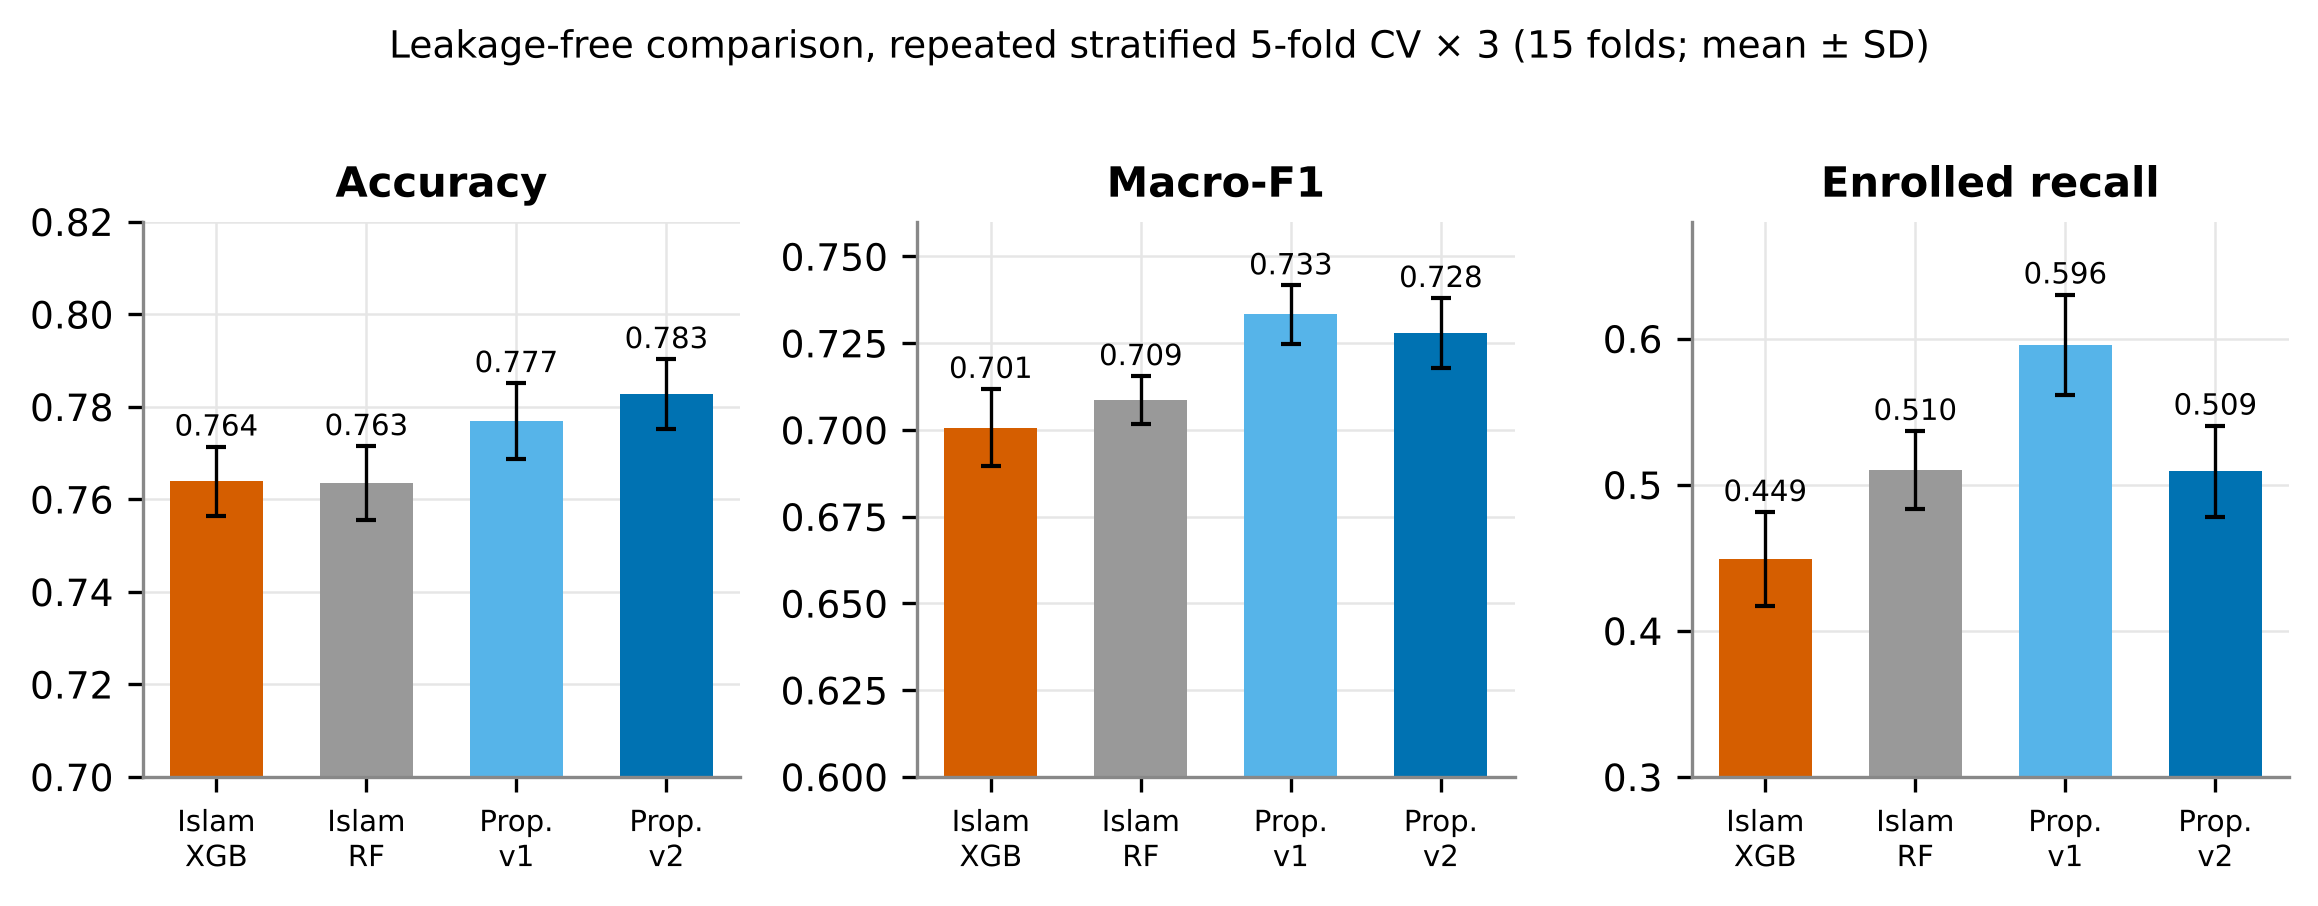

paper_figures/fig7_paired_folds.png


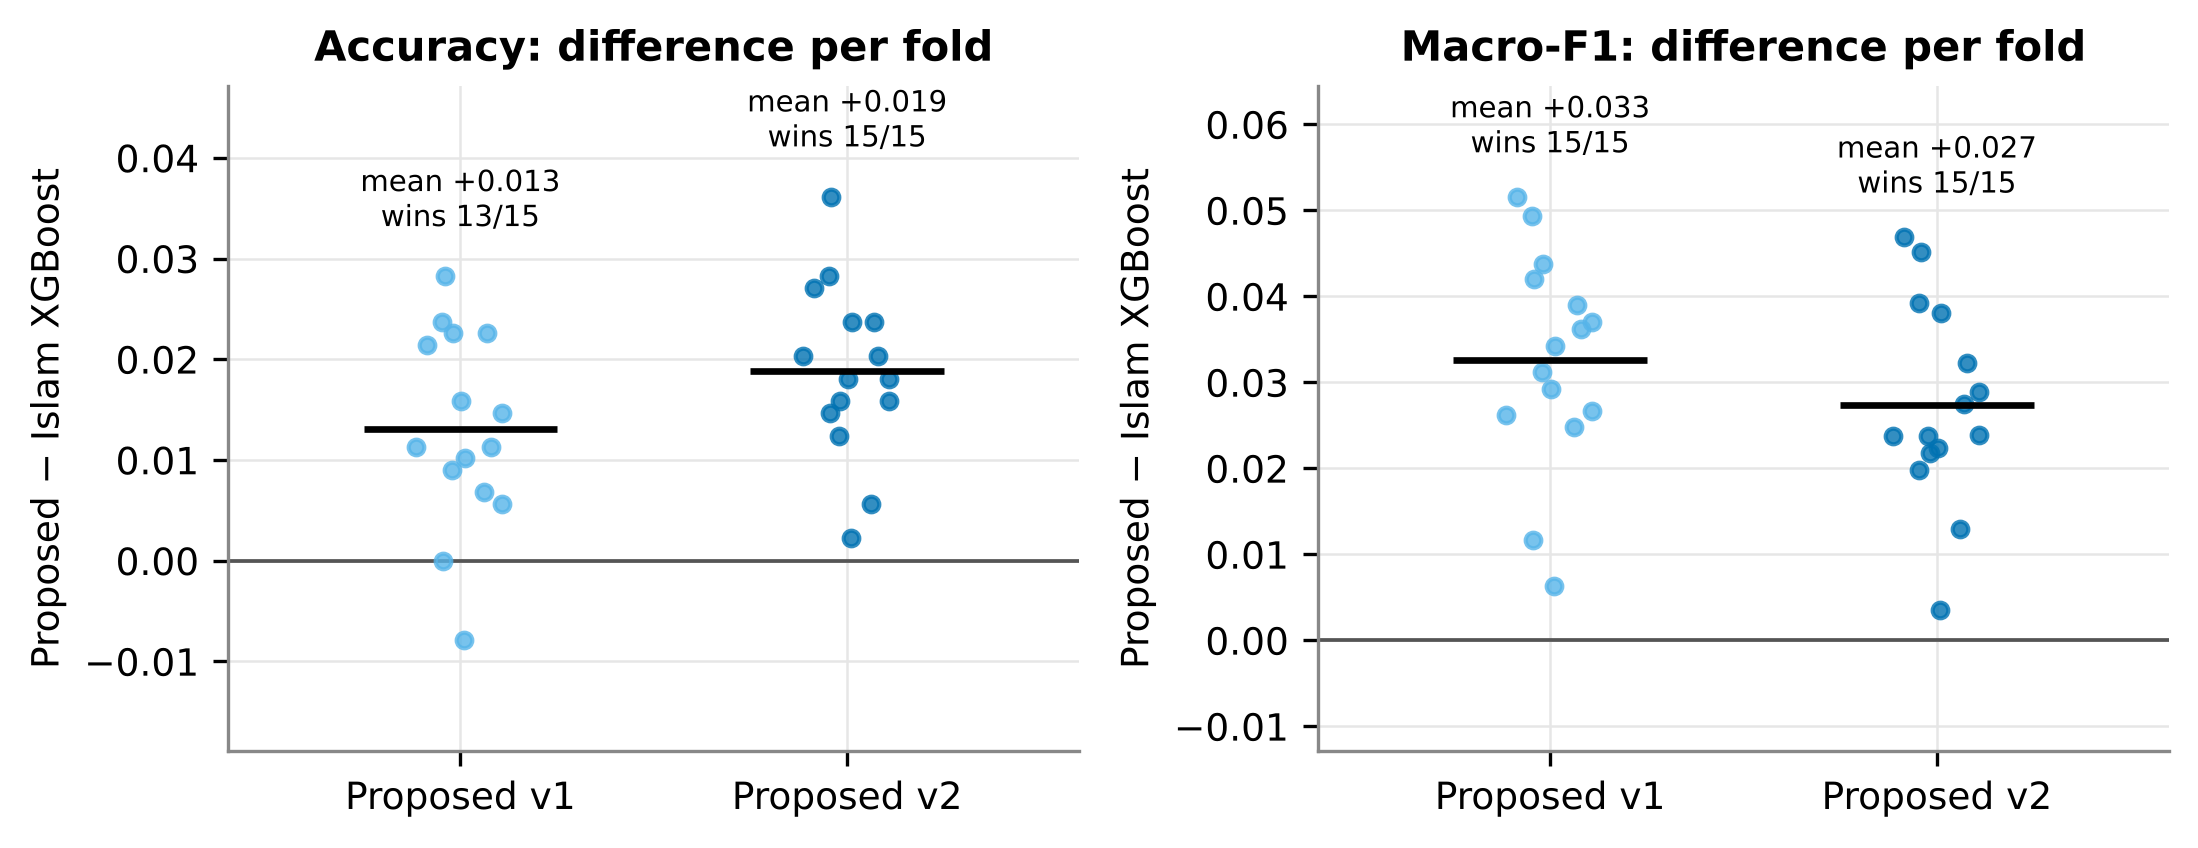

paper_figures/fig8_confusion.png


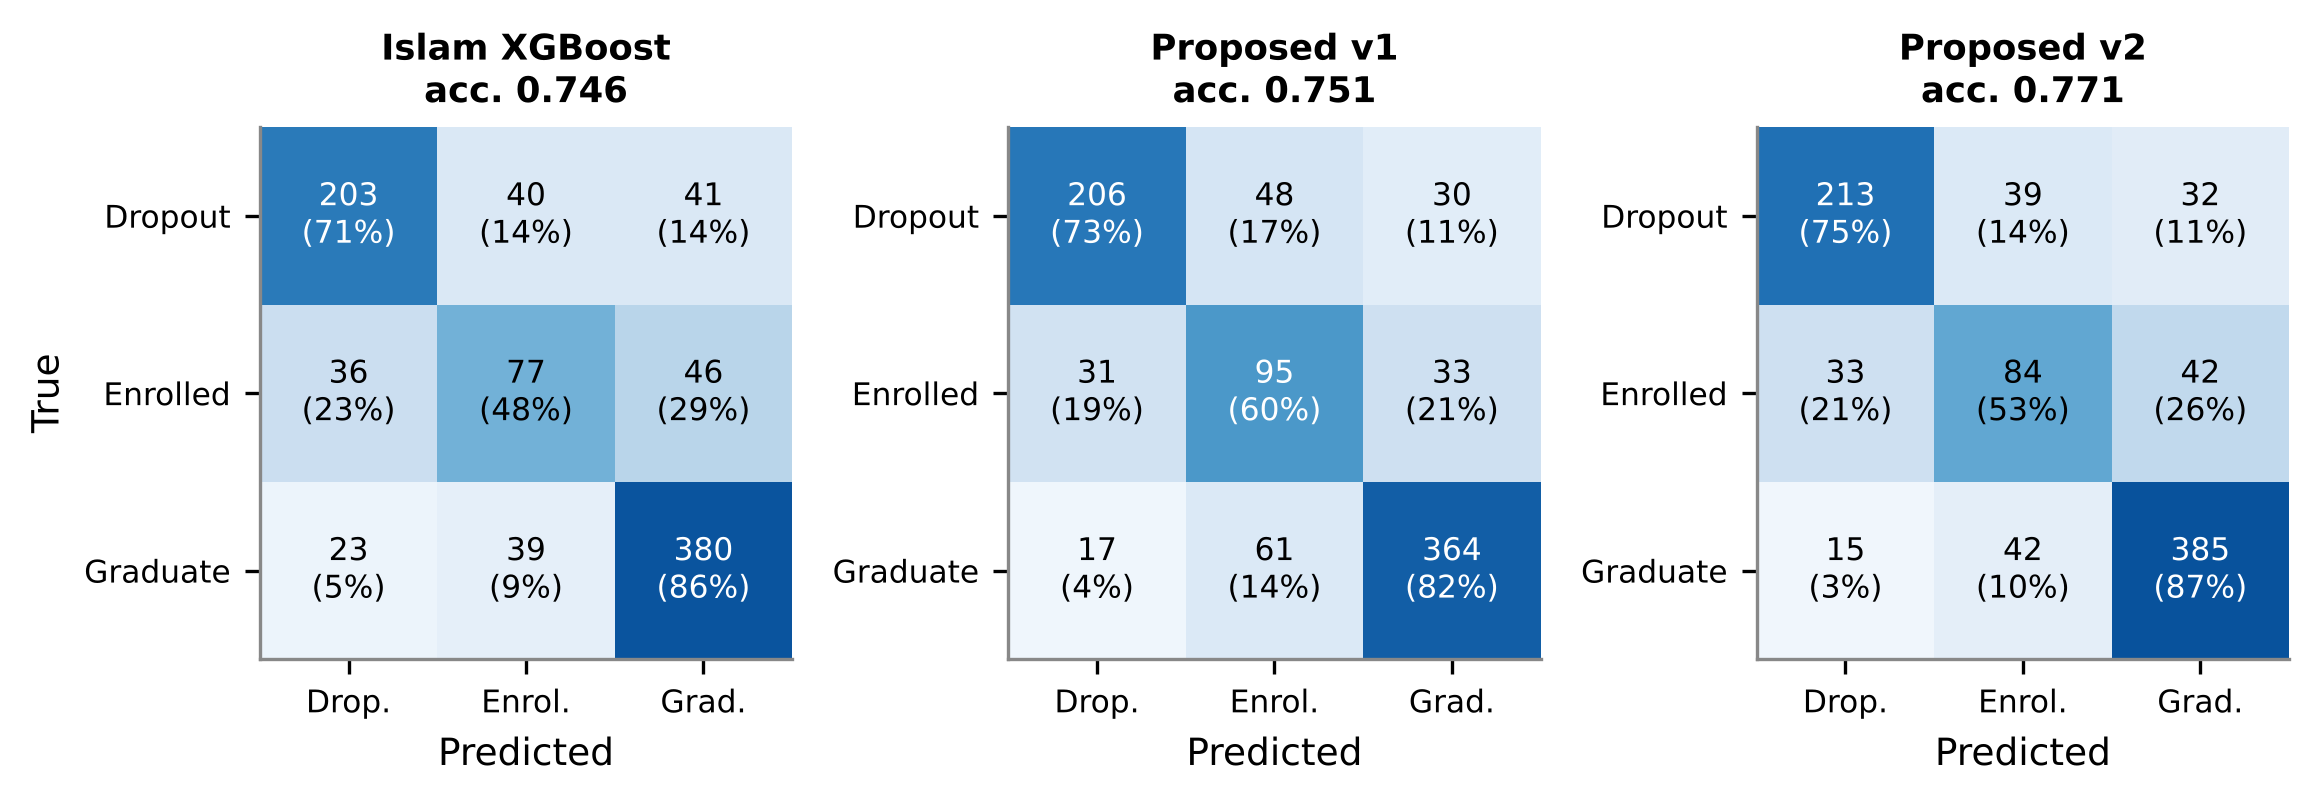

paper_figures/fig9_ablation.png


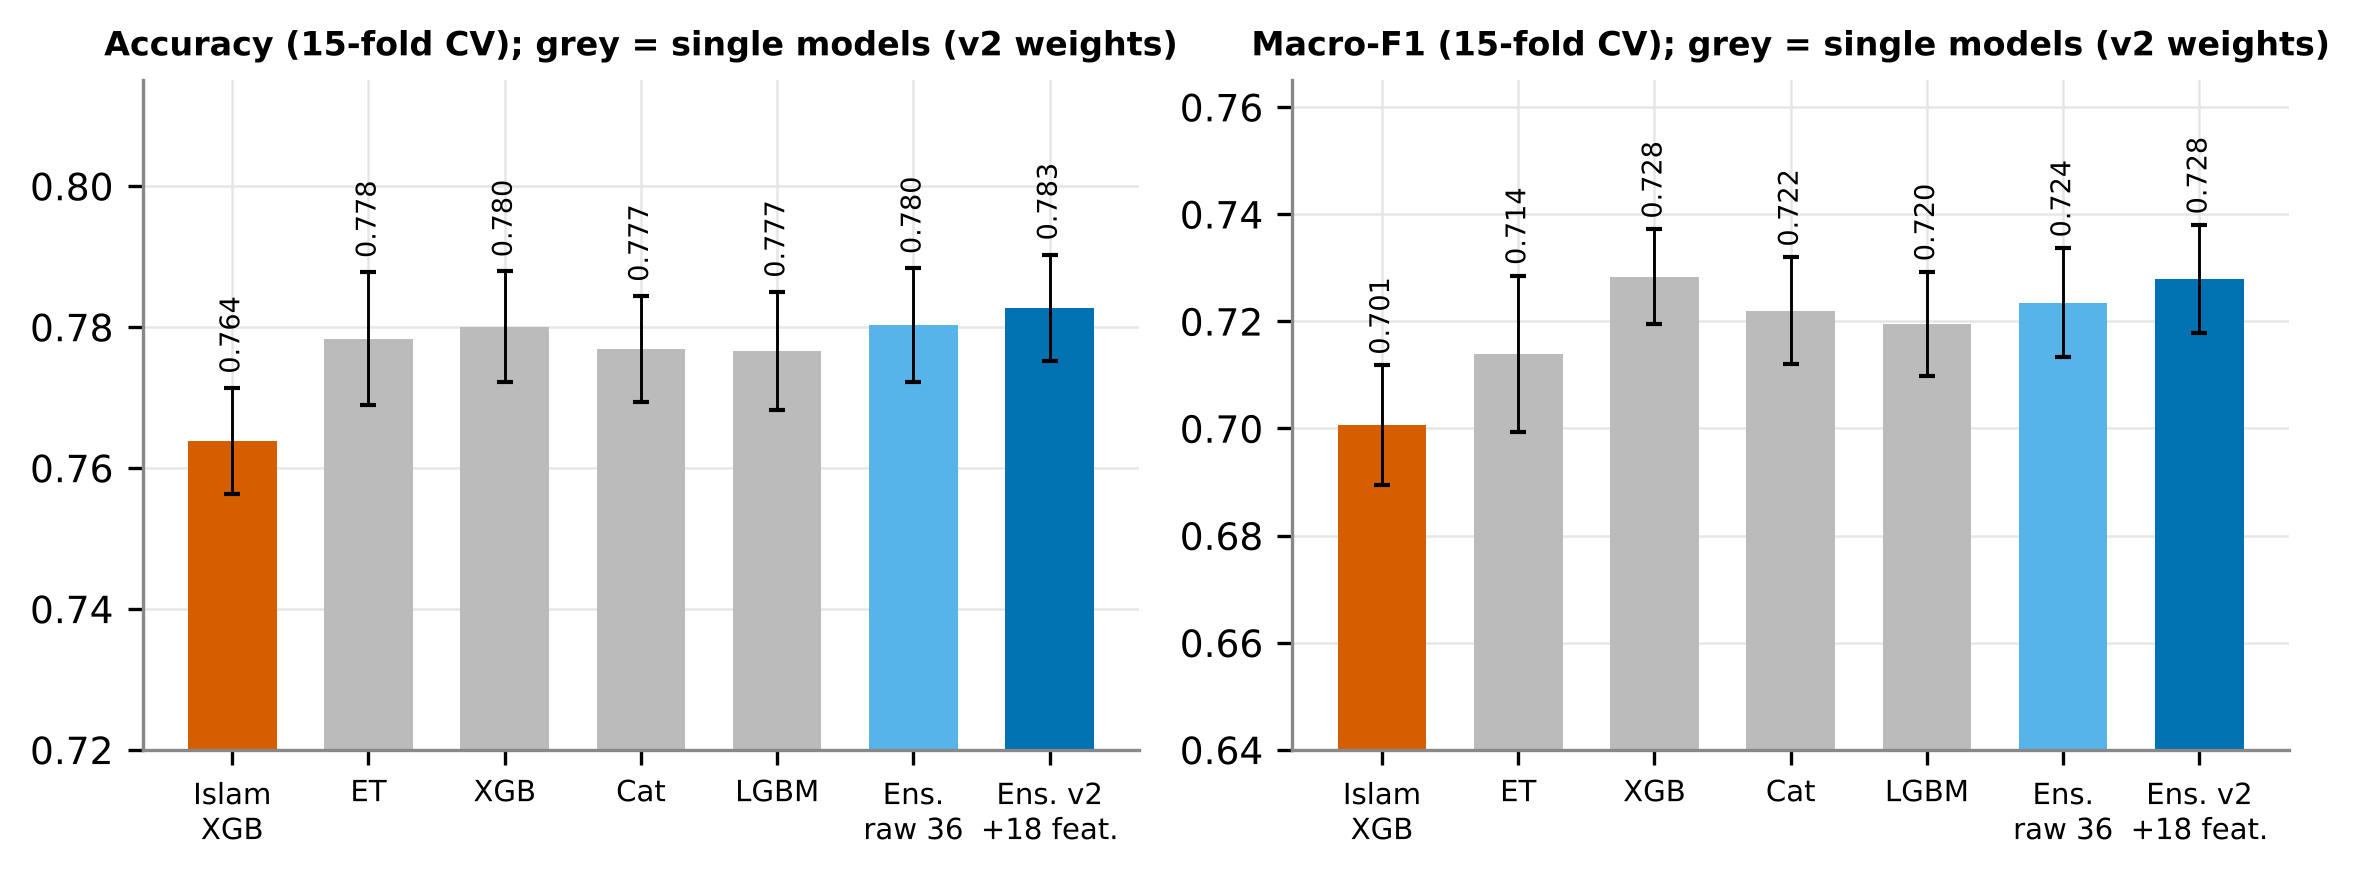

In [ ]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('paper_figures/*.png'))[:11]:
    print(f); display(Image(f, width=700))

## 6. Use the proposed model on your own split (example)
Train the cost-sensitive ensemble on 80 % of the students and score the other 20 %.

In [ ]:
import sys; sys.path.insert(0, "/content/dropout-prediction/src")
import numpy as np
from sklearn.model_selection import train_test_split
from common import *

df, X, y = load_data(); XF = add_features(X)                       # 36 raw -> 54 features
tr, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)
members = [Model("lgbm", BASE_LGB, "sqrt"),                         # "sqrt" = class weights (n / (K n_c))^0.5
           Model("cat", dict(iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=5), "sqrt"),
           Model("xgb", dict(n_estimators=300, max_depth=4, learning_rate=0.05, min_child_weight=3, reg_lambda=5), "sqrt"),
           Model("et", {}, "sqrt")]
members = [m.fit(XF.iloc[tr], y[tr]) for m in members]
proba = np.mean([m.predict_proba(XF.iloc[te]) for m in members], axis=0)   # soft vote
pred = proba.argmax(1)
print(metrics(y[te], pred))
print("first 3 students:", dict(zip(CLASS_NAMES, proba[0].round(3))))


{'accuracy': 0.7706214689265537, 'macro_f1': np.float64(0.7182586293353467), 'f1_Dropout': np.float64(0.781651376146789), 'f1_Enrolled': np.float64(0.5185185185185185), 'f1_Graduate': np.float64(0.8546059933407325), 'recall_Dropout': np.float64(0.75), 'recall_Enrolled': np.float64(0.5283018867924528), 'recall_Graduate': np.float64(0.8710407239819005), 'precision_Dropout': np.float64(0.8160919540229885), 'precision_Enrolled': np.float64(0.509090909090909), 'precision_Graduate': np.float64(0.8387799564270153)}
first 3 students: {'Dropout': np.float64(0.052), 'Enrolled': np.float64(0.016), 'Graduate': np.float64(0.932)}
